In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from matplotlib import font_manager
font_manager.fontManager.addfont("../../../arial.ttf")
plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 18,
    "pdf.fonttype": 42,       # Embed TrueType fonts in PDF
})

/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
data = sc.read_h5ad("../experiment/plants_experiment3_predict_process_cluster_7_11/predict_end_cluster_7_11.h5ad")
#data_filtered = data[data.obs["day_types"].isin([14,16,18,20])].copy()
print(data.obs["day_types"].unique())
data_filtered = data[data.obs["day_types"].isin([13,14,15,16,17,18,19,20])].copy()
#data_filtered = data.copy()
# print(data)
print(data.obs["weight_types"].unique())
print(data.obs["day_types"].unique())
print(data.obs["cluster_types"].unique())
# print(data.obs["infer_train_mark"].unique())
print("predict filetered data:",data_filtered)
print(data_filtered.obs["weight_types"].unique())
print(data_filtered.obs["day_types"].unique())
print(data_filtered.obs["cluster_types"].unique())
# print(data_filtered.obs["infer_train_mark"].unique())
print("Has duplicate index:", data.obs.index.has_duplicates)
print(data.obs[data.obs.index.duplicated(keep=False)])
print(data.var_names)


[12. 13. 14. 15. 16. 17. 18. 19. 20. 21.]
[0.         0.11111111 0.22222222 0.33333333 0.44444444 0.55555556
 0.66666667 0.77777778 0.88888889 1.        ]
[12. 13. 14. 15. 16. 17. 18. 19. 20. 21.]
[7, 11]
Categories (2, int64): [7, 11]
predict filetered data: AnnData object with n_obs × n_vars = 16000 × 39337
    obs: 'weight_types', 'day_types', 'cluster_types', 'infer_train_mark'
[0.11111111 0.22222222 0.33333333 0.44444444 0.55555556 0.66666667
 0.77777778 0.88888889]
[13. 14. 15. 16. 17. 18. 19. 20.]
[7, 11]
Categories (2, int64): [7, 11]
Has duplicate index: False
Empty DataFrame
Columns: [weight_types, day_types, cluster_types, infer_train_mark]
Index: []
Index(['GLYMA_01G000100', 'GLYMA_01G000200', 'GLYMA_01G000300',
       'GLYMA_01G000400', 'GLYMA_01G000500', 'GLYMA_01G000600',
       'GLYMA_01G000700', 'GLYMA_01G000800', 'GLYMA_01G000900',
       'GLYMA_01G001000',
       ...
       'GLYMA_20G248900', 'GLYMA_20G249100', 'GLYMA_20G249300',
       'GLYMA_20G249400', 'GLYMA_20G2

In [3]:
train_data = sc.read_h5ad("../../input/exp3_train_cluster_0_7_11_adata.h5ad")
print("train original data:", train_data)
train_data.obs["day_types"] = train_data.obs["day"]
train_data.obs["cluster_types"] = train_data.obs["Group"]
train_data.obs.loc[train_data.obs["day"] == 12, "weight_types"] = 0
train_data.obs.loc[train_data.obs["day"] == 21, "weight_types"] = 1

print(train_data.obs["weight_types"].unique())
print(train_data.obs["day_types"].unique())
print(train_data.obs["cluster_types"].unique())

train original data: AnnData object with n_obs × n_vars = 3912 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'day', 'Group'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
[0. 1.]
[12, 21]
Categories (2, int64): [12, 21]
[0, 7, 11]
Categories (3, int64): [0, 7, 11]


In [4]:
import anndata as ad
interp = ad.concat([data_filtered, train_data], axis=0, join="inner")
#new start
interp.X = interp.X.astype("float64")
# interp = interp_all.copy()
#new end
# print(interp_all)
# print(interp_all.obs["weight_types"].unique())
# print(interp_all.obs["day_types"].unique())
# print(interp_all.obs["cluster_types"].unique())
idx = interp.obs.sort_values(["day_types", "cluster_types"]).index
interp_all = interp[idx].copy()
# interp_all = interp_1[interp_1.obs["cluster_types"].sort_values().index].copy()
print(interp_all)
print(interp_all.obs["weight_types"].unique())
print(interp_all.obs["day_types"].unique())
print(interp_all.obs["cluster_types"].unique())

/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/anndata/_core/merge.py:1111: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


AnnData object with n_obs × n_vars = 19912 × 39337
    obs: 'weight_types', 'day_types', 'cluster_types'
[0.         0.11111111 0.22222222 0.33333333 0.44444444 0.55555556
 0.66666667 0.77777778 0.88888889 1.        ]
[12. 13. 14. 15. 16. 17. 18. 19. 20. 21.]
[0, 7, 11]
Categories (3, int64): [0, 7, 11]


computing PCA
    with n_comps=50
    finished (0:03:14)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:17)
computing Diffusion Maps using n_comps=15(=n_dcs)
computing transitions
    finished (0:00:00)
    eigenvalues of transition matrix
    [1.         0.9965372  0.995167   0.9942099  0.99226886 0.98694634
     0.98572356 0.9815654  0.9794865  0.97687477 0.9747099  0.967326
     0.9665233  0.9624706  0.9614357 ]
    finished: added
    'X_diffmap', diffmap coordinates (adata.obsm)
    'diffmap_evals', eigenvalues of transition matrix (adata.uns) (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
running PAGA
    finished: added

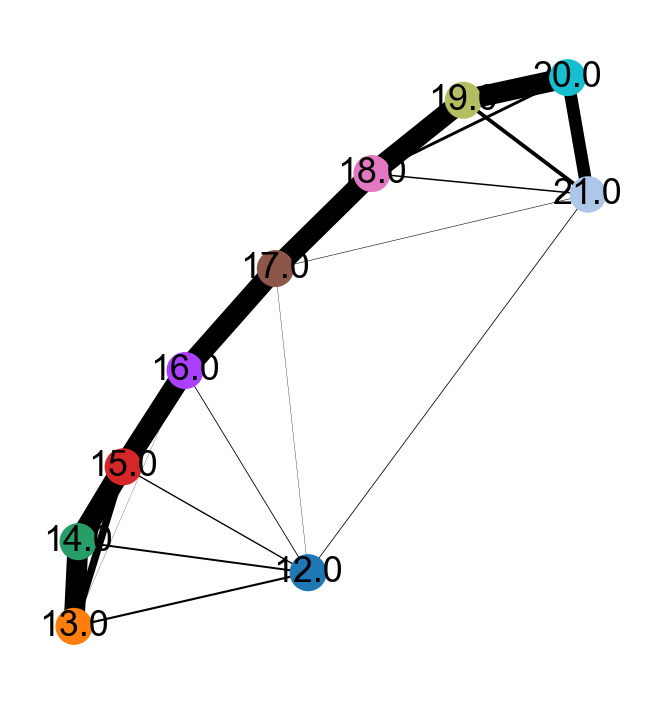

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:17)
Root cells: 2026
computing Diffusion Pseudotime using n_dcs=10
    finished: added
    'dpt_pseudotime', the pseudotime (adata.obs) (0:00:00)


In [5]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

sc.settings.verbosity = 3
sc.settings.set_figure_params(
    dpi=100,
    frameon=False,
    figsize=(4, 4),
    facecolor="white"
)
interp_all_ann = interp_all.copy()

# cluster_types used for embedding_density grouping
interp_all_ann.obs["cluster_types"] = (
    interp_all_ann.obs["cluster_types"]
    .astype(str)
    .astype("category")
)

# day_types used for PAGA trajectory
interp_all_ann.obs["day_types"] = pd.to_numeric(interp_all_ann.obs["day_types"])
interp_all_ann.obs["day_types"] = interp_all_ann.obs["day_types"].astype("category")
# PCA
#original
# sc.pp.pca(interp_all_ann)
sc.tl.pca(interp_all_ann, svd_solver="arpack")
sc.pp.neighbors(interp_all_ann, n_neighbors=15, n_pcs=30)

sc.tl.diffmap(interp_all_ann)
sc.pp.neighbors(interp_all_ann)


# PAGA using day_types
sc.tl.paga(interp_all_ann, groups="day_types")

sc.pl.paga(
    interp_all_ann,
    color=["day_types"]
)

# UMAP initialized by PAGA
# sc.tl.umap(
#     interp_all_ann,
#     init_pos="paga",
#     random_state=0
# )
sc.tl.umap(interp_all_ann)


# Choose root from starting day
root_day = 12   # change to 12 if numeric, or another starting day

root_mask = interp_all_ann.obs["day_types"] == root_day

print("Root cells:", root_mask.sum())

interp_all_ann.uns["iroot"] = np.flatnonzero(root_mask)[0]

# DPT pseudotime
sc.tl.dpt(interp_all_ann)

# # Scale to 0-1
# pt = interp_all_ann.obs["dpt_pseudotime"]

# interp_all_ann.obs["pseudotime_0_1"] = (
#     (pt - pt.min()) / (pt.max() - pt.min())
# )



AAACGAAAGCGCAATG-1-batch-nodule_small    False
AAACGAAAGTAGGAAG-1-batch-nodule_small    False
AAACGCTCACATGACT-1-batch-nodule_small    False
AAACGCTTCTTGTGCC-1-batch-nodule_small    False
AAAGAACAGGTCATAA-1-batch-nodule_small    False
                                         ...  
TTTACGTCAGATACTC-1-batch-nodule_large    False
TTTACTGGTGTGAATA-1-batch-nodule_large    False
TTTCAGTAGCTGTACT-1-batch-nodule_large    False
TTTCAGTAGGTTCATC-1-batch-nodule_large    False
TTTCAGTCATTGAGGG-1-batch-nodule_large    False
Length: 19912, dtype: bool


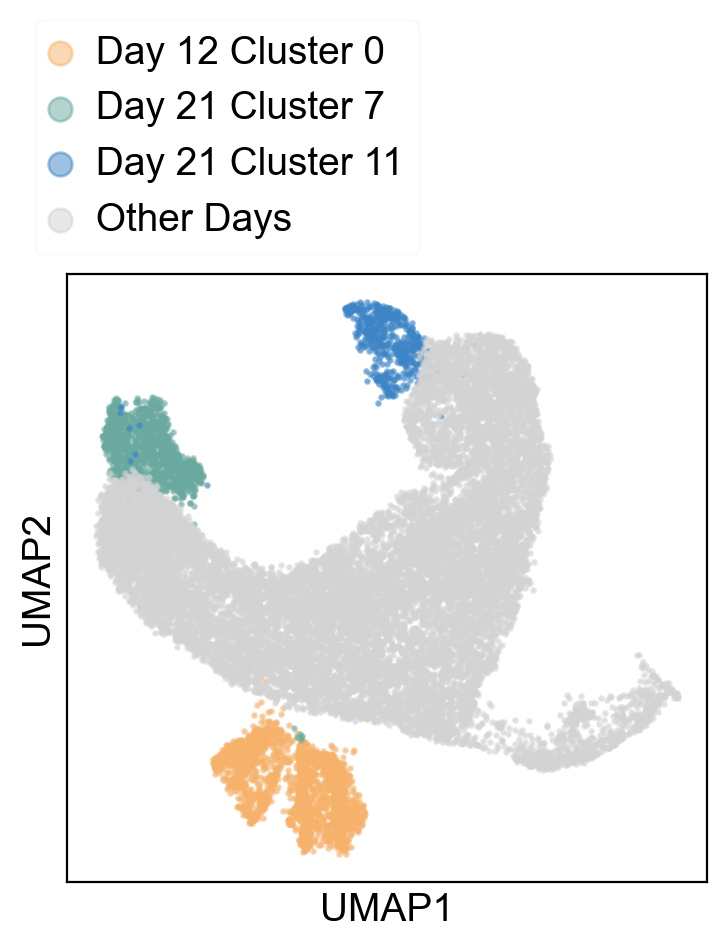

In [6]:

fig,ax = plt.subplots(figsize=(4.1, 4))
X_umap = interp_all_ann.obsm["X_umap"]

mask_12 = interp_all_ann.obs["day_types"] == 12

mask_21_7 = (
    (interp_all_ann.obs["day_types"] == 21) &
    (interp_all_ann.obs["cluster_types"] == '7')
)

print(mask_21_7)
mask_21_11 = (
    (interp_all_ann.obs["day_types"] == 21) &
    (interp_all_ann.obs["cluster_types"] == '11')
)

mask_other = ~interp_all_ann.obs["day_types"].isin([12, 21])

plt.scatter(
    X_umap[mask_12, 0],
    X_umap[mask_12, 1],
    c="#F6B26B",
    s=2,
    alpha=0.5,
    label=" Day 12 Cluster 0"
)

plt.scatter(
    X_umap[mask_21_7, 0],
    X_umap[mask_21_7, 1],
    c="#6AA99F",
    s=2,
    alpha=0.5,
    label=" Day 21 Cluster 7"
)

plt.scatter(
    X_umap[mask_21_11, 0],
    X_umap[mask_21_11, 1],
    c="#3D85C6",
    s=2,
    alpha=0.5,
    label=" Day 21 Cluster 11"
)

plt.scatter(
    X_umap[mask_other, 0],
    X_umap[mask_other, 1],
    c="lightgray",
    s=2,
    alpha=0.5,
    label=" Other Days"
)
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)
ax.set_xticks([])
ax.set_yticks([])
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.25, 1.45),
    markerscale=6,
    scatterpoints=1,
    prop={"size": 14, "weight": "bold"},
    frameon=True,
    facecolor="white",
    edgecolor="lightgray",
    framealpha=0.1
)
#plt.axis("off")
# plt.title("combined umap marked training data")
fig.savefig(os.path.join(f"exp3_umap_with_training_data_cells_order_change.pdf"), bbox_inches="tight")
plt.show()
# plt.legend()
# handles, labels = ax.get_legend_handles_labels()
# legend_fig = plt.figure(figsize=(3, 1.5))

# legend = legend_fig.legend(
#     handles,
#     labels,
#     loc="center",
#     markerscale=6,
#     scatterpoints=1,
#     prop={"size": 8, "weight": "bold"},
#     frameon=True,
#     facecolor="white",
#     edgecolor="lightgray",
#     framealpha=0.1
# )

# # Crop the PDF to the legend
# legend_fig.canvas.draw()
# bbox = legend.get_window_extent().transformed(
#     legend_fig.dpi_scale_trans.inverted()
# )

# legend_fig.savefig(
#     "umap_legend.pdf",
#     bbox_inches=bbox,
#     pad_inches=0.05
# )

# plt.show()



View of AnnData object with n_obs × n_vars = 2000 × 39337
    obs: 'weight_types', 'day_types', 'cluster_types', 'dpt_pseudotime'
    uns: 'pca', 'neighbors', 'diffmap_evals', 'paga', 'day_types_sizes', 'day_types_colors', 'umap', 'iroot'
    obsm: 'X_pca', 'X_diffmap', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
     cluster_types day_types  dpt_pseudotime
1000             7      13.0        0.327672
1001             7      13.0        0.348272
1002             7      13.0        0.348216
1003             7      13.0        0.375790
1004             7      13.0        0.347597


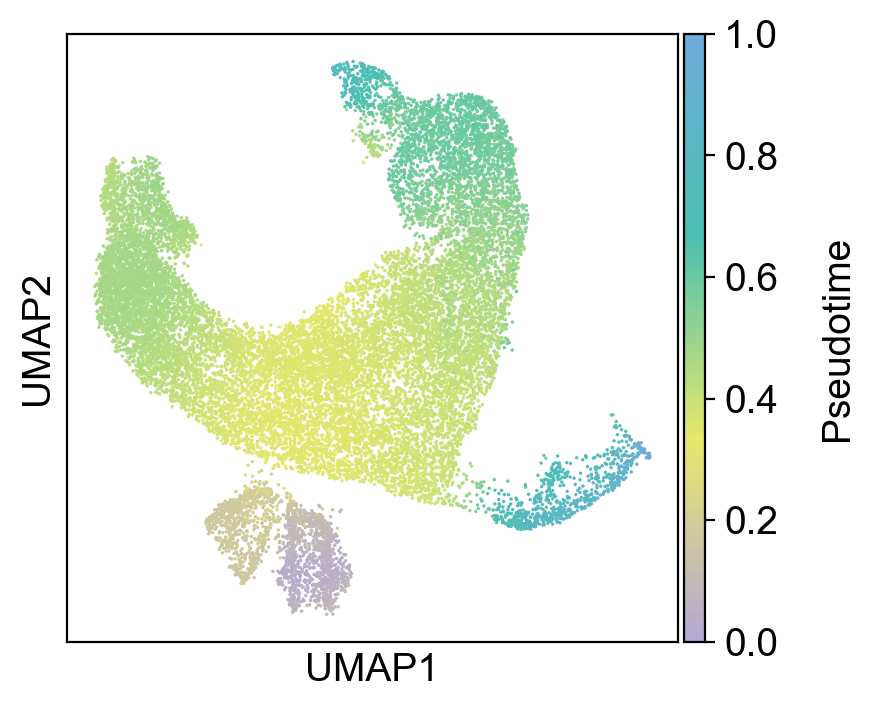

In [7]:
from matplotlib.colors import LinearSegmentedColormap
# fig = plt.subplots(figsize=(4, 4))
fig, ax = plt.subplots(figsize=(4.3, 4))
my_cmap = LinearSegmentedColormap.from_list(
    "my_pseudotime",
    ["#B4A7D6","#E6E86A","#4AC1B0","#6FABDC"]
)

sc.pl.umap(
    interp_all_ann,
    color="dpt_pseudotime",
    cmap=my_cmap,
    title="",
    na_color="black",
    ax=ax,
    show=False
)
mask_13 = interp_all_ann.obs["day_types"] == 13
print(interp_all_ann[mask_13])
print(interp_all_ann.obs.loc[mask_13, ["cluster_types", "day_types","dpt_pseudotime"]].head())
# fig = plt.gcf()

# fig = plt.gcf()
ax.set_axis_on()
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(True)

ax.set_xticks([])
ax.set_yticks([])
cbar_ax = fig.axes[-1]
cbar_ax.set_ylabel("Pseudotime", rotation=90, labelpad=15)
cbar_ax.yaxis.set_label_position("right")
# fig.savefig(setting["filename"], bbox_inches="tight")
# plt.show()
# plt.close(fig)
fig.savefig(os.path.join(f"exp3_paga_0to1_cells_order_change.pdf"), bbox_inches="tight")
plt.show()

computing density on 'umap'
--> added
    'umap_density_cluster_types', densities (adata.obs)
    'umap_density_cluster_types_params', parameter (adata.uns)


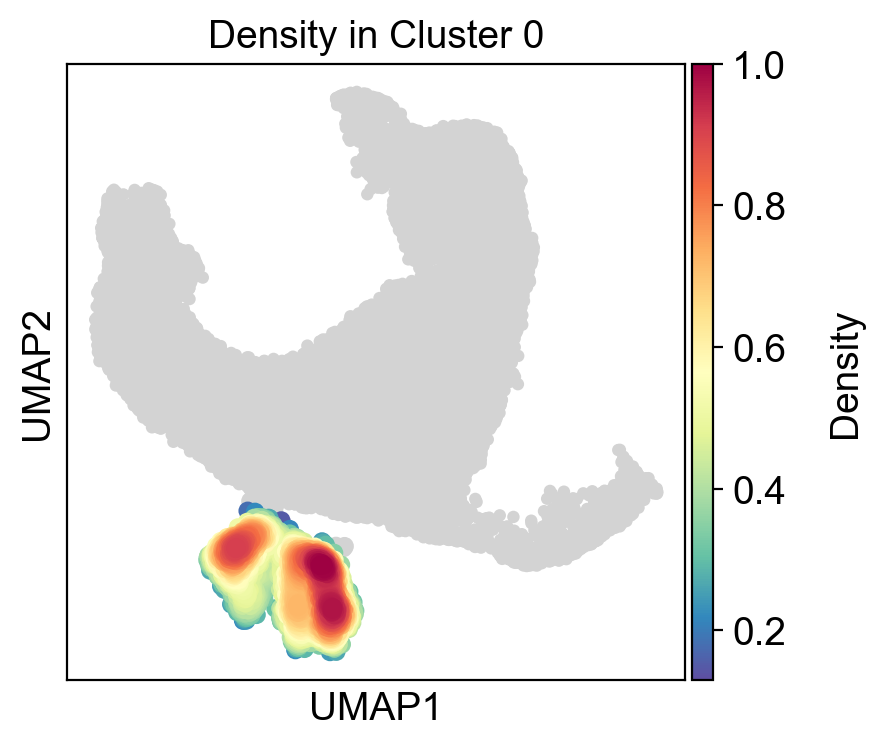

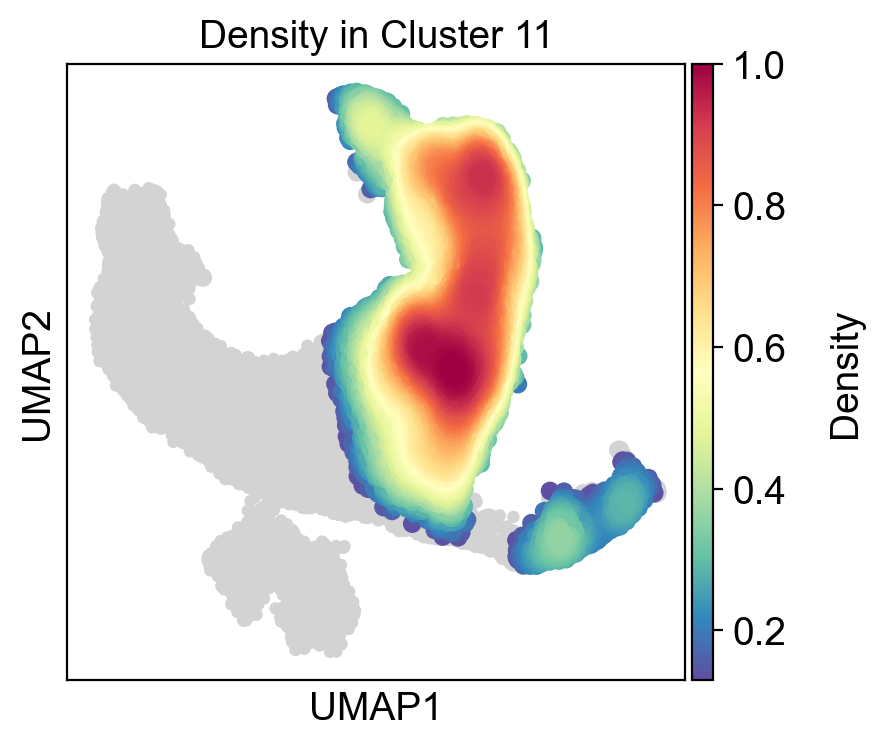

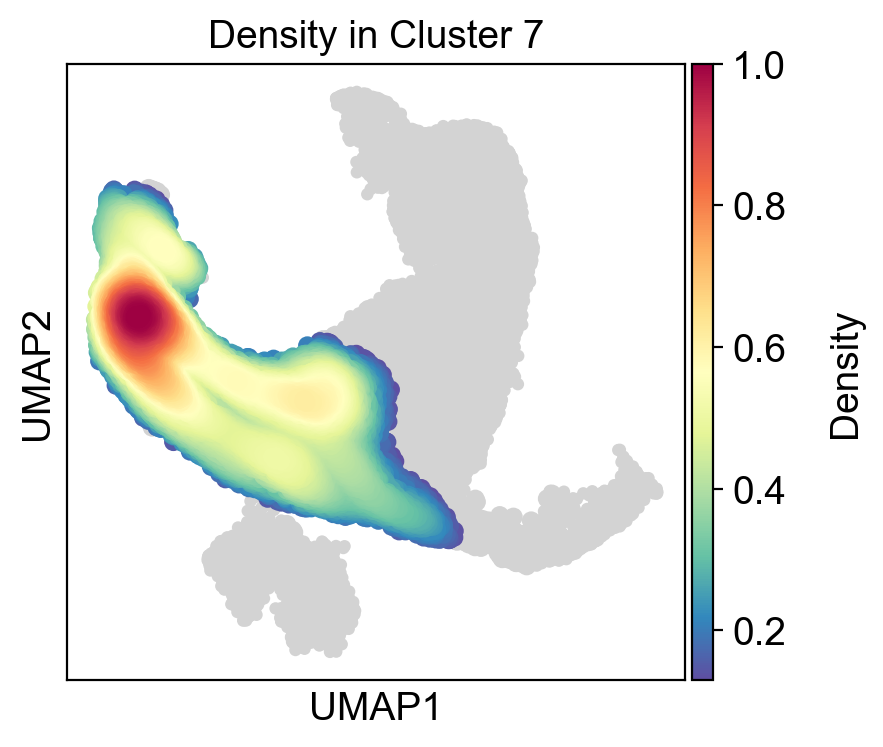

In [8]:
sc.tl.embedding_density(
    interp_all_ann,
    basis="umap",
    groupby="cluster_types"
)

groups = interp_all_ann.obs["cluster_types"].cat.categories[:3]

my_cmap = LinearSegmentedColormap.from_list(
    "my_density",
    ["#e6e86a", "#4AC1B0", "#b4a7d6"]
)

for g in groups:
    #fig, ax = plt.subplots(figsize=(4, 5))

    sc.pl.embedding_density(
        interp_all_ann,
        basis="umap",
        groupby="cluster_types",
        group=g,
        color_map="Spectral_r",
        vmin=0.13,
        title=f"Density in Cluster {g}",
        show=False
    )
    # Get the figure and UMAP axes created by Scanpy
    fig = plt.gcf()
    ax = fig.axes[0]
    fig.set_size_inches(4.3, 4)
    ax.set_axis_on()
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(True)

    ax.set_xticks([])
    ax.set_yticks([])

    cbar_ax = fig.axes[-1]
    cbar_ax.set_ylabel(f"Density", rotation=90, labelpad=15)
    cbar_ax.yaxis.set_label_position("right")
    plt.savefig(
        os.path.join(f"umap_density_cluster_{g}_cells_order_change.pdf"),
        bbox_inches="tight"
    )


In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

interp_all_ann.obs["day_types_num"] = pd.to_numeric(
    interp_all_ann.obs["day_types"]
)

cluster_settings = {
    "0": {
        "color": "#F6B26B",
        "title": "Days in Cluster 0",
        "filename": "umap_days_cluster_0_cells_order_change.pdf"
    },
    "7": {
        "color": "#6AA99F",
        "title": "Days in Cluster 7",
        "filename": "umap_days_cluster_7_cells_order_change.pdf"
    },
    "11": {
        "color": "#3D8567",
        "title": "Days in Cluster 11",
        "filename": "umap_days_cluster_11_cells_order_change.pdf"
    }
}
X_umap = interp_all_ann.obsm["X_umap"]

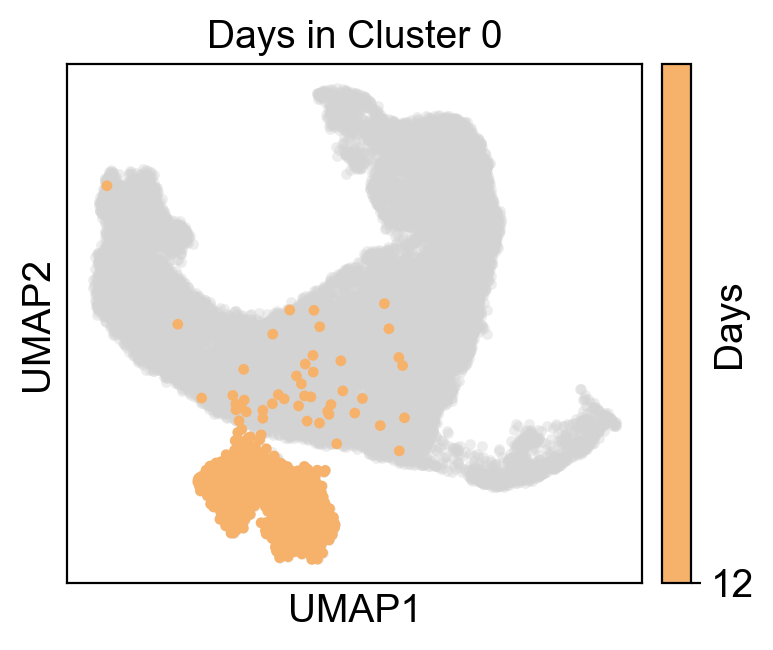

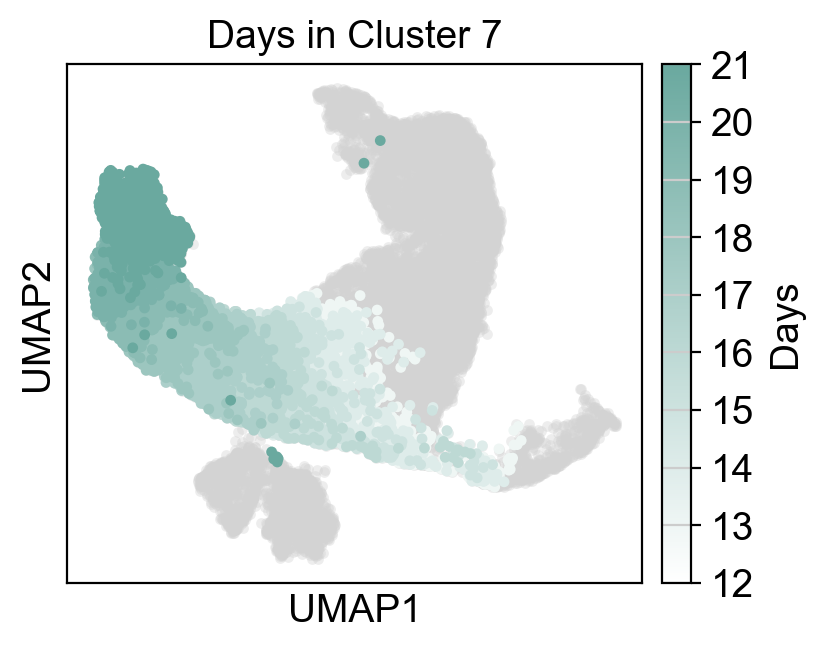

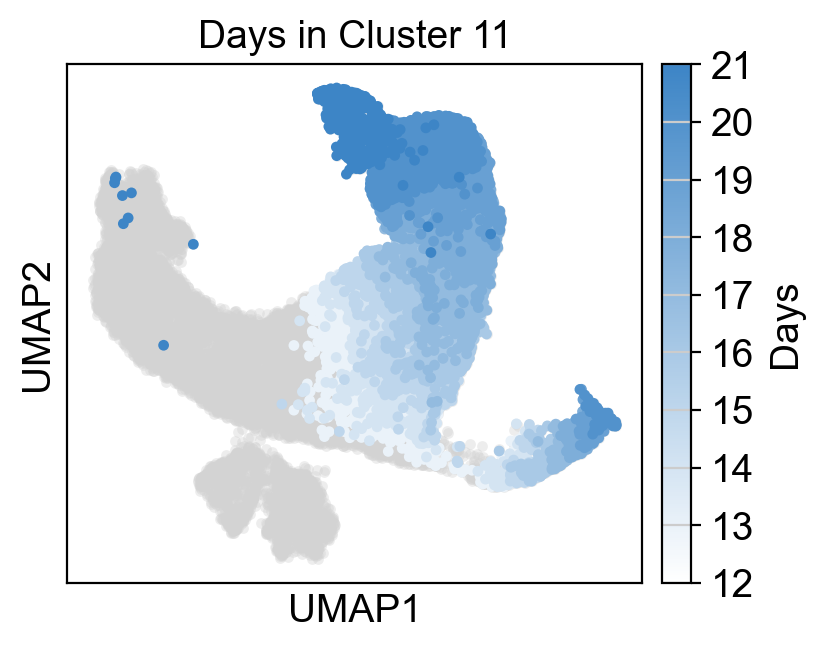

In [10]:

# X_umap = interp_all_ann.obsm["X_umap"]

for cluster_id, setting in cluster_settings.items():
    cluster_id = str(cluster_id)
    fig, ax = plt.subplots(figsize=(4, 5))
    # fig.set_size_inches(4, 5)

    # Gray background
    ax.scatter(
        X_umap[:, 0], X_umap[:, 1],
        c="lightgray", s=15, alpha=0.4,
        linewidths=0
    )

    mask = (
        interp_all_ann.obs["cluster_types"].astype(str) == cluster_id
    ).to_numpy()

    if not mask.any():
        plt.close(fig)
        continue

    days = interp_all_ann.obs.loc[mask, "day_types_num"].to_numpy()
    custom_colors = {
        "0": ["#F6B26B"],                       # One solid color
        "7": ["white", "#6AA99F"],
        "11": ["white", "#3D85C6"]
    }

    colors = custom_colors[cluster_id]

    if len(colors) == 1:
        cmap = mcolors.ListedColormap(colors)
    else:
        cmap = mcolors.LinearSegmentedColormap.from_list(
            f"cluster_{cluster_id}", colors
        )

    points = ax.scatter(
        X_umap[mask, 0], X_umap[mask, 1],
        c=days,
        cmap=cmap,
        vmin=12,
        vmax=21,
        s=15,
        linewidths=0
    )

    # Graph border and labels
    ax.set_axis_on()
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.set_title(setting["title"])
    ax.set_aspect("equal")
    ax.grid(False)

    for spine in ax.spines.values():
        spine.set_visible(True)

    ax.set_xticks([])
    ax.set_yticks([])

    # Colorbar matched to the graph height
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.1)

    cbar = fig.colorbar(points, cax=cax)
    cbar.set_label("Days", rotation=90, labelpad=5)

    if cluster_id == "0":
        cbar.set_ticks(sorted(set(days)))
        cbar.set_label("Days", rotation=90, labelpad=-15)
    else:
        cbar.set_ticks(range(12, 22))
    fig.savefig(
        os.path.join(f"exp3_cluster_{cluster_id}_days_change.pdf"),
        bbox_inches="tight"
    )
    # fig.savefig(setting["filename"], bbox_inches="tight")
    plt.show()
    plt.close(fig)

    pseudotime_point cluster_types  cell_number
0               0.00             0            1
3               0.01             0           26
6               0.02             0           69
9               0.03             0          138
12              0.04             0          176
    pseudotime_point cluster_types  cell_number  accumulated_cell_number
0               0.00             0            1                        1
3               0.01             0           26                       27
6               0.02             0           69                       96
9               0.03             0          138                      234
12              0.04             0          176                      410
cat categories: Index(['0', '11', '7'], dtype='object')


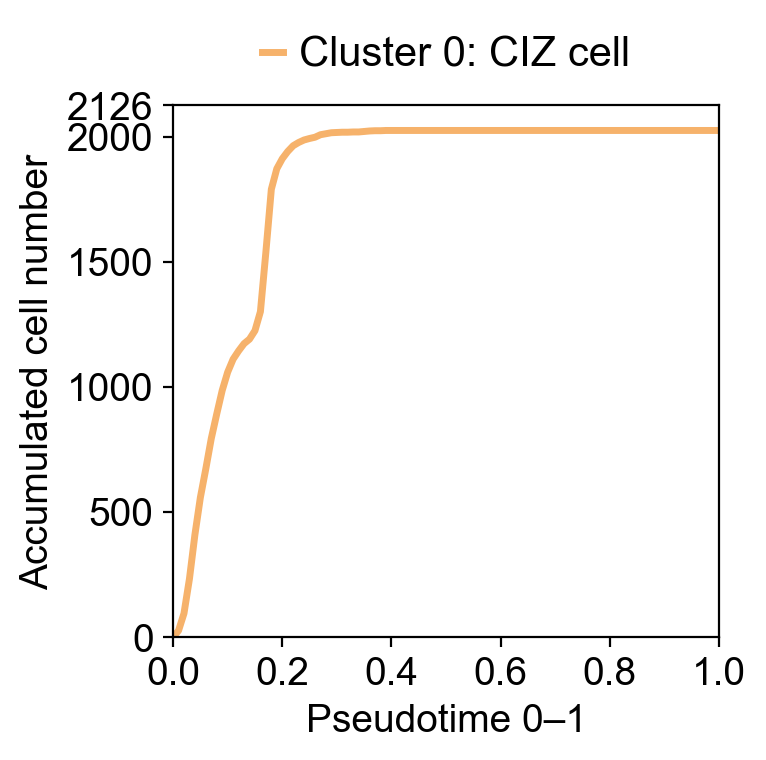

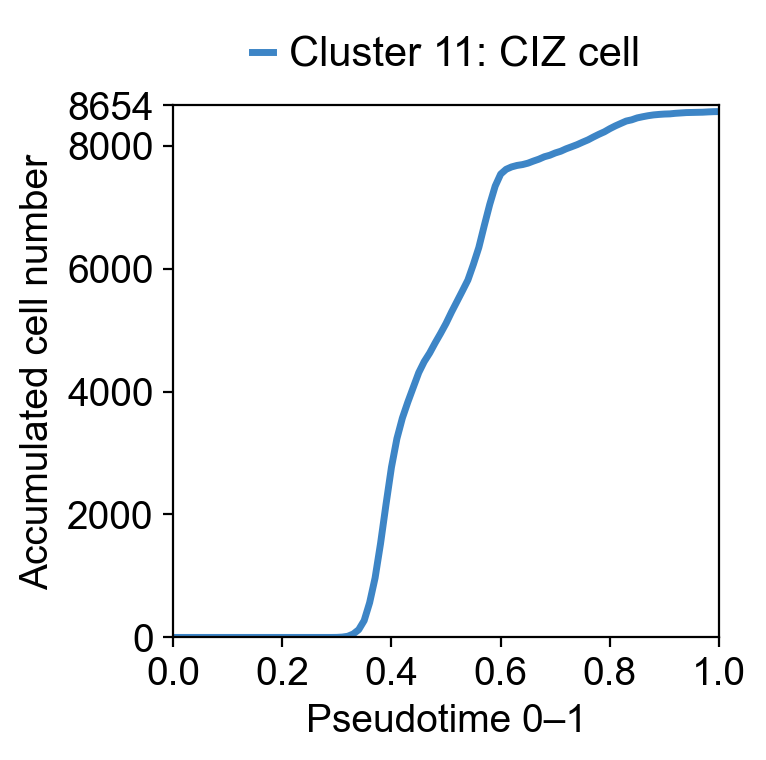

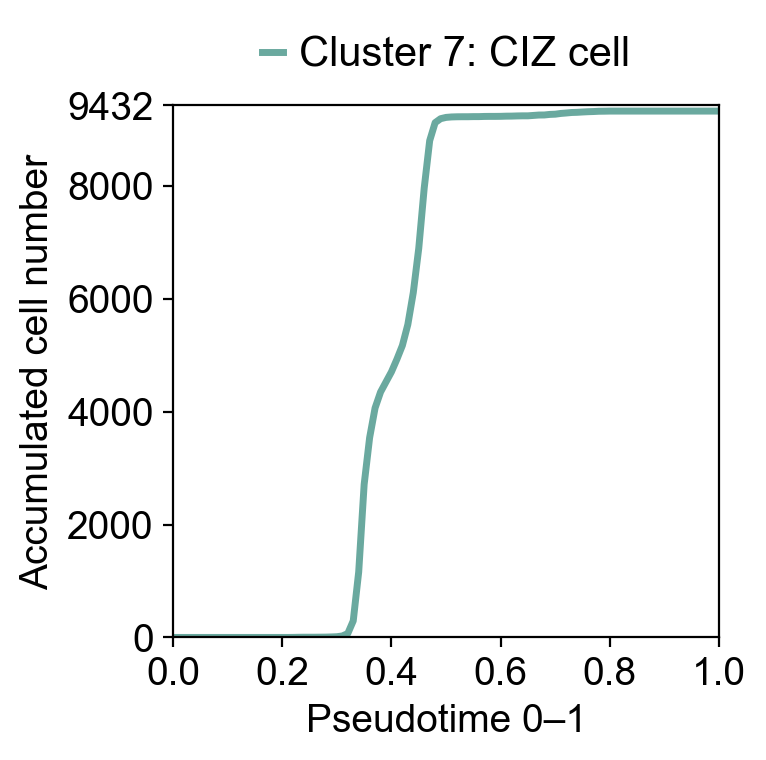

In [11]:
adata = interp_all_ann.copy()
adata.obs["pseudotime_point"] = adata.obs["dpt_pseudotime"].round(2)

count_df = (
    adata.obs
    .groupby(["pseudotime_point", "cluster_types"], observed=False)
    .size()
    .reset_index(name="cell_number")
)

# Sort for plotting
count_df = count_df.sort_values(["cluster_types", "pseudotime_point"])

print(count_df.head())
count_df["accumulated_cell_number"] = (
    count_df
    .groupby("cluster_types", observed=False)["cell_number"]
    .cumsum()
)

print(count_df.head())


print("cat categories:",adata.obs["cluster_types"].cat.categories)
# one figure for each cluster
cluster_colors = {
    "0": "#F6B26B",
    "7": "#6AA99F",
    "11": "#3D85C6"
}
for clust in adata.obs["cluster_types"].cat.categories:

    tmp = count_df[count_df["cluster_types"] == clust].copy()
    tmp = tmp.sort_values("pseudotime_point")

    fig, ax = plt.subplots(figsize=(3.5, 3.5))
    # if clust == 0:
    ax.plot(
        tmp["pseudotime_point"],
        tmp["accumulated_cell_number"],
        marker="o",
        linewidth=2.5,
        markersize=0.1,
        color=cluster_colors[str(clust)],
        label=f"Cluster {clust}: CIZ cell"
    )
    # elif clust ==7:
    #     ax.plot(
    #         tmp["pseudotime_point"],
    #         tmp["accumulated_cell_number"],
    #         marker="o",
    #         linewidth=2.5,
    #         markersize=0.1,
    #         color=cluster_colors[str(clust)],
    #         label=f"Cluster {clust}: CIZ cell"
    #     )
    # else:


    ax.set_xlabel("Pseudotime 0–1")
    ax.set_ylabel("Accumulated cell number")
    # ax.set_title(f"Cluster {clust}")

    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, 1.2),
        frameon=False,
        fontsize=15
    )
    # X-axis: 0 to 1, ticks every 0.2
    ax.set_xlim(0, 1)
    ax.set_xticks(np.linspace(0, 1, 6))

    # Y-axis: smallest to largest accumulated cell count
    ymin = int(tmp["accumulated_cell_number"].min())
    ymax = int(tmp["accumulated_cell_number"].max())+100

    if clust == '0':
        ax.set_ylim(0, ymax)
        ax.set_yticks(np.append(np.arange(0, ymax, 500), ymax))
    elif clust =='7':
        ax.set_ylim(0, ymax)
        ax.set_yticks(np.append(np.arange(0, ymax, 2000), ymax))
    elif clust =='11':
        ax.set_ylim(0, ymax)
        ax.set_yticks(np.append(np.arange(0, ymax, 2000), ymax))
        # ax.set_yticks(
        #     np.unique(np.linspace(ymin, ymax, 5).round().astype(int))
        # )
    ax.grid(False)
    # int(np.floor(np.arange(ymin, ymax, 500) / 100) * 100)
    # int(np.ceil(ymax / 100) * 100)
    fig.savefig(
        os.path.join(f"exp3_accumulated_density_cluster_{clust}_cells_order_change.pdf"),
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

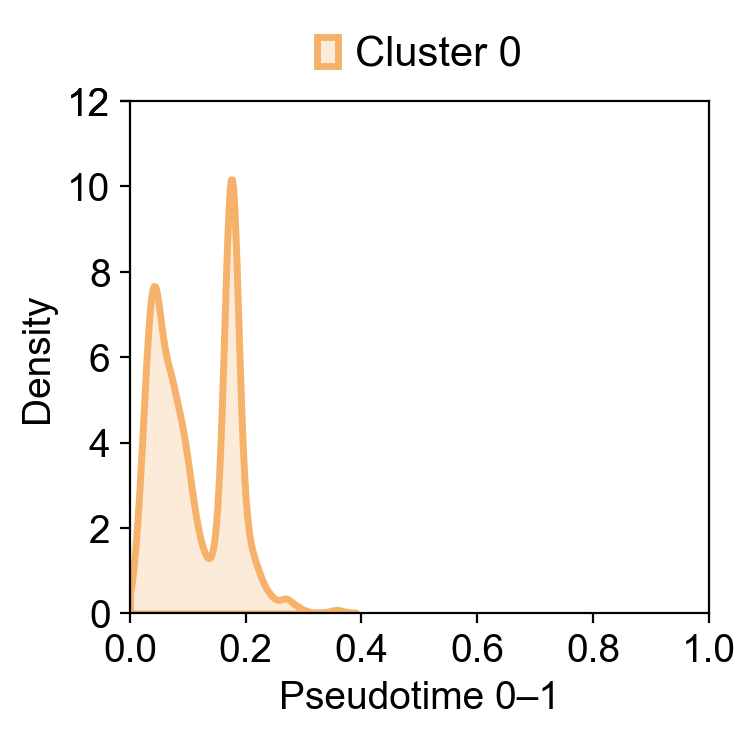

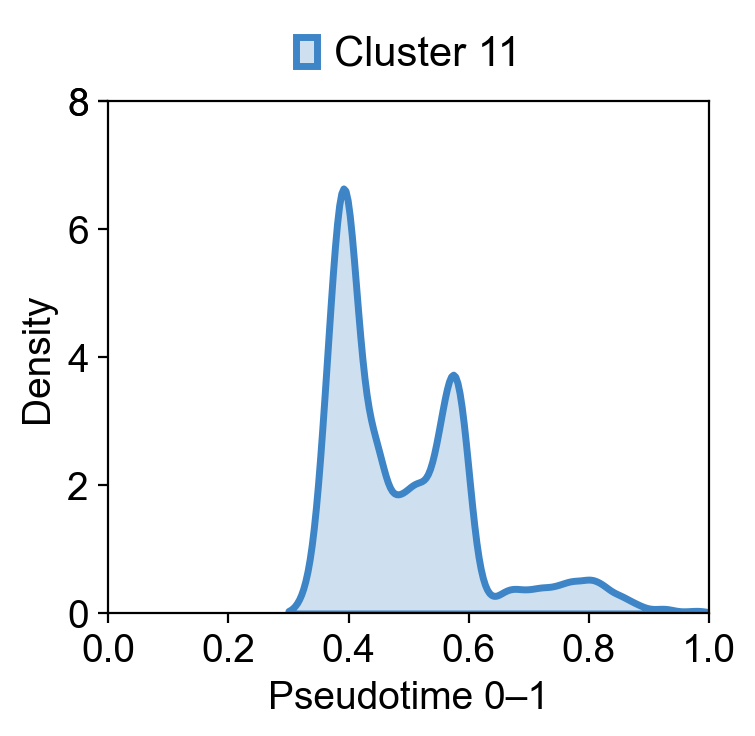

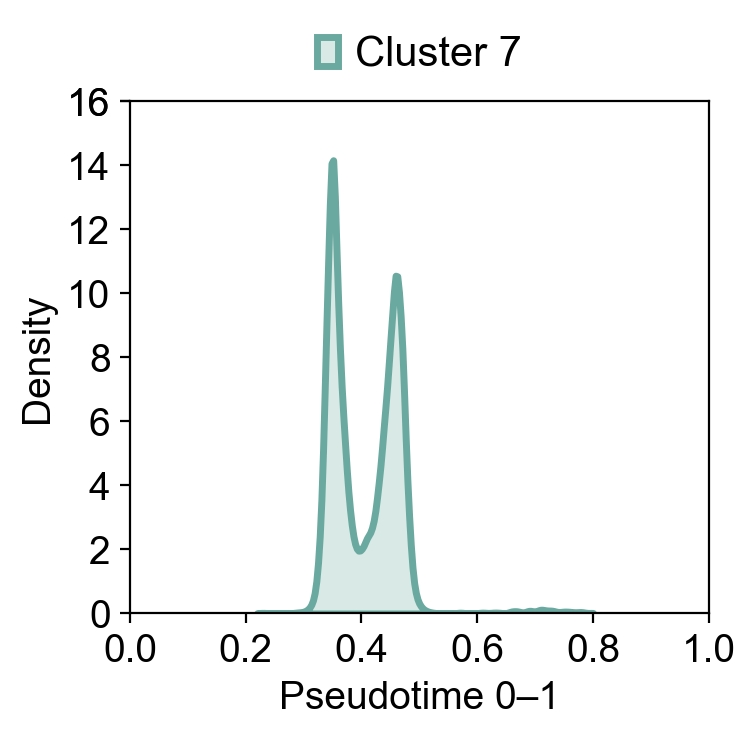

In [12]:

plot_df = adata.obs[
    ["pseudotime_point", "cluster_types"]
].dropna().copy()

plot_df["cluster_types"] = plot_df["cluster_types"].astype(str)

# for clust in adata.obs["cluster_types"].cat.categories:
#     clust = str(clust)
#     tmp = plot_df[plot_df["cluster_types"] == clust].copy()
for clust in adata.obs["cluster_types"].cat.categories:
    clust = str(clust)
    tmp = plot_df[plot_df["cluster_types"] == clust].copy()
    tmp = tmp.sort_values("pseudotime_point")

    fig, ax = plt.subplots(figsize=(4, 4))

    sns.kdeplot(
        data=tmp,
        x="pseudotime_point",
        common_norm=False,
        bw_adjust=0.6,
        cut=0,
        clip=(0, 1),
        fill=True,
        alpha=0.25,
        linewidth=2.5,
        color=cluster_colors[str(clust)],
        label=f"Cluster {clust}",
        ax=ax
    )
  
    # X-axis: 0 to 1, ticks every 0.2
    ax.set_xlim(0, 1)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.set_xlabel("Pseudotime 0–1")
    ax.set_ylabel("Density")
    # ax.set_title(f"Cluster {clust}")
    # print(tmp["pseudotime_point"])
    # Y-axis: smallest to largest accumulated cell count
    # ymin = float(tmp["pseudotime_point"].min())
    # ymax = float(tmp["pseudotime_point"].max())+1
    # print(ymax)
    if clust == '0':
        ax.set_ylim(0, 12)
        ax.set_yticks(np.append(np.arange(0, 13, 2), 12))
    elif clust =='7':
        ax.set_ylim(0, 16)
        ax.set_yticks(np.append(np.arange(0, 17, 2), 16))
    elif clust =='11':
        ax.set_ylim(0, 8)
        ax.set_yticks(np.append(np.arange(0, 9, 2), 8))
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, 1.2),
        frameon=False,
        fontsize=15
    )
    ax.grid(False)
    # x_start = tmp['pseudotime_point'].min()
    # ax.set_xticks(sorted([x_start] + list(ax.get_xticks())))
    # ax.margins(x=0, y=0)
    plt.tight_layout()
    plt.savefig(
        f"density_pseudotime_cluster_{clust}_cells_order_change.pdf",
        bbox_inches="tight",
        dpi=300
    )
    plt.show()
    plt.close(fig)